In [113]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")

include("../util_shoji.jl")


sor (generic function with 1 method)

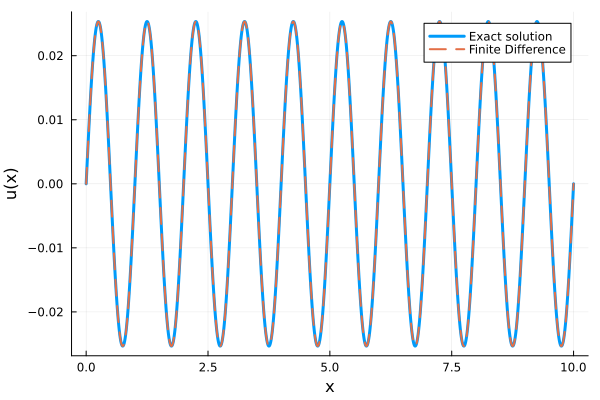

In [115]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.001
T = 10.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# u'' =  - sin(2πx)
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = - 2.0
    if i > 1
        A[i,i-1] =  1.0
    end
    if i < n
        A[i,i+1] = 1.0
    end
end

A ./= (dt)^2

# Right-hand side
f =  - sin.(2π .* xi)

# Solve linear system
u_interior = A \ f
#u_interior = sor(A, f)

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = (1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [103]:




X_train = collect(0:dt:T)
y_train = -sin.(2π .* X_train)



println("X_train:", X_train)
println("y_train:", y_train)

println(y_train.size)

 
#

X_train:[0.0, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017, 0.018, 0.019, 0.02, 0.021, 0.022, 0.023, 0.024, 0.025, 0.026, 0.027, 0.028, 0.029, 0.03, 0.031, 0.032, 0.033, 0.034, 0.035, 0.036, 0.037, 0.038, 0.039, 0.04, 0.041, 0.042, 0.043, 0.044, 0.045, 0.046, 0.047, 0.048, 0.049, 0.05, 0.051, 0.052, 0.053, 0.054, 0.055, 0.056, 0.057, 0.058, 0.059, 0.06, 0.061, 0.062, 0.063, 0.064, 0.065, 0.066, 0.067, 0.068, 0.069, 0.07, 0.071, 0.072, 0.073, 0.074, 0.075, 0.076, 0.077, 0.078, 0.079, 0.08, 0.081, 0.082, 0.083, 0.084, 0.085, 0.086, 0.087, 0.088, 0.089, 0.09, 0.091, 0.092, 0.093, 0.094, 0.095, 0.096, 0.097, 0.098, 0.099, 0.1, 0.101, 0.102, 0.103, 0.104, 0.105, 0.106, 0.107, 0.108, 0.109, 0.11, 0.111, 0.112, 0.113, 0.114, 0.115, 0.116, 0.117, 0.118, 0.119, 0.12, 0.121, 0.122, 0.123, 0.124, 0.125, 0.126, 0.127, 0.128, 0.129, 0.13, 0.131, 0.132, 0.133, 0.134, 0.135, 0.136, 0.137, 0.138, 0.139, 0.14, 0.141, 0.142, 0.143, 

Excessive output truncated after 524302 bytes.

0.9976125063612252, 0.9980267284282716, 0.998401550108975, 0.9987369566060175, 0.9990329346781247, 0.9992894726405892, 0.9995065603657316, 0.9996841892832999, 0.999822352380809, 0.9999210442038161, 0.9999802608561371, 1.0, 0.9999802608561371, 0.9999210442038161, 0.999822352380809, 0.9996841892832999, 0.9995065603657316, 0.9992894726405892, 0.9990329346781247, 0.9987369566060175, 0.998401550108975, 0.9980267284282716, 0.9976125063612252, 0.9971589002606139, 0.9966659280340299, 0.9961336091431725, 0.99556196460308, 0.9949510169813002, 0.9943007903969988, 0.9936113105200084, 0.9928826045698137, 0.9921147013144779, 0.9913076310695066, 0.9904614256966512, 0.989576118602651, 0.988651744737914, 0.9876883405951378, 0.986685944207868, 0.985644595148998, 0.9845643345292054, 0.9834452049953297, 0.9822872507286887, 0.9810905174433341, 0.979855052384247, 0.9785809043254721, 0.9772681235681935, 0.9759167619387473, 0.9745268727865771, 0.9730985109821264, 0.971631732914674, 0.9701265964901059, 0.96858

In [104]:
#ℓ = best_ℓ
ℓ = 0.2
σf = 0.01
C = 0.01

l=1000.0
σf=0.001
C=0.001


# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, T, length=300))
# -------------------------
# Covariance Matrices
# -------------------------



function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = - 2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(X_train), dt)

#println("H:", H)
##println("H.size:", H.size)



#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I

K =
    H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H' +
#    σn^2 * I
     C * (dt)^4 * I
#K +=  10e-6*I


#println("H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H':", H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H')

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

println("K.size:", K.size)

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

#println("Ks.size:", Ks.size)

Ks = H * Ks

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

#println("Kss.size:", Kss.size)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

300-element Vector{Float64}:
 3.16228017704673e-8
 3.151289732649733e-8
 3.1402399191714205e-8
 3.1285162515622655e-8
 3.1229505184037694e-8
 3.1105119613962396e-8
 3.106972601427218e-8
 3.090436252332527e-8
 3.07608041163283e-8
 3.076248033147601e-8
 ⋮
 3.072285659944251e-8
 3.088446804476983e-8
 3.102858036901703e-8
 3.1106797697764665e-8
 3.1192592913463745e-8
 3.129899795615271e-8
 3.1408049633822735e-8
 3.151743617885658e-8
 3.1622785029517655e-8

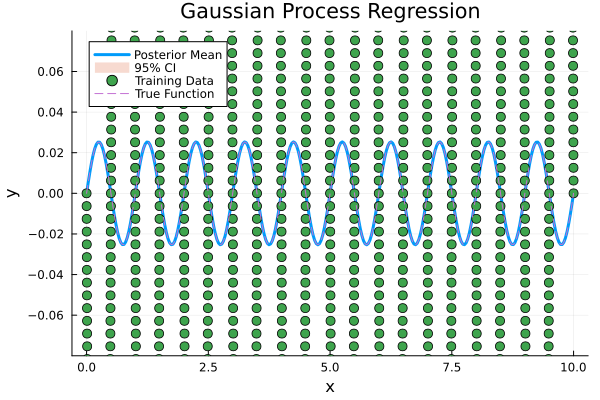

"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [105]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.08, 0.08),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")

display(current())

savefig("a.png")

In [94]:
function log_marginal_H(
    X_train,
    y;
    H,
    dt,
    ℓ,
    σf,
    C,
    prior_mean = 0.0
)

    K =
        H *
        kernel_matrix(X_train, X_train;
                      ℓ=ℓ,
                      σf=σf) *
        H' +
        C * (dt)^4 * I
    #K +=  10e-6*I


    m = fill(prior_mean, length(y))

    L = cholesky(Hermitian(K)).L
    α = L' \ (L \ (y - m))

    logdetK = 2sum(log.(diag(L)))

    

    return -0.5 * ((y - m)' * α) -
           0.5 * logdetK -
           0.5 * length(y) * log(2π)
end



log_marginal_H (generic function with 1 method)

In [95]:
ℓ_grid = [ 0.0001, 0.001,0.1,0.5,1.0,2.0,5.0,10.0,100.0, 1000]

σf_grid = [0.001,0.01,0.03,
           0.1,0.3,1.0,3.0,
           10.0,30.0,100.0,500.0, 1000.0, 10000.0]

C_grid = [1]

ℓ_grid  = 10 .^ range(-3, 3, length=5)
σf_grid = 10 .^ range(-3, 3, length=5)
C_grid  = 10 .^ range(-3, 3, length=5)

scores = zeros(length(ℓ_grid),
               length(σf_grid),
               length(C_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)
        for (k,C) in enumerate(C_grid)
            println("parameters:", ℓ, σf, C)

            scores[i,j,k] =
                log_marginal_H(
                    X_train,
                    y_train;
                    H=H,
                    dt=dt,
                    ℓ=ℓ,
                    σf=σf,
                    C=C,
                    prior_mean=0.0
                )

        end
    end
end

best_linear_idx = argmax(scores)
best_I = CartesianIndices(scores)[best_linear_idx]

best_ℓ  = ℓ_grid[best_I[1]]
best_σf = σf_grid[best_I[2]]
best_C  = C_grid[best_I[3]]
println("l=", best_ℓ)
println("σf=", best_σf)
println("C=", best_C)
best_loglik =
    log_marginal_H(
        X_train,
        y_train;
        H=H,
        dt=dt,
        ℓ=best_ℓ,
        σf=best_σf,
        C=best_C,
        prior_mean=0.0
    )

println("log marginal likelihood (best) = ", best_loglik)



parameters:0.0010.0010.001
parameters:0.0010.0010.03162277660168379
parameters:0.0010.0011.0
parameters:0.0010.00131.622776601683793
parameters:0.0010.0011000.0
parameters:0.0010.031622776601683790.001
parameters:0.0010.031622776601683790.03162277660168379
parameters:0.0010.031622776601683791.0
parameters:0.0010.0316227766016837931.622776601683793
parameters:0.0010.031622776601683791000.0
parameters:0.0011.00.001
parameters:0.0011.00.03162277660168379
parameters:0.0011.01.0
parameters:0.0011.031.622776601683793
parameters:0.0011.01000.0
parameters:0.00131.6227766016837930.001
parameters:0.00131.6227766016837930.03162277660168379
parameters:0.00131.6227766016837931.0
parameters:0.00131.62277660168379331.622776601683793
parameters:0.00131.6227766016837931000.0
parameters:0.0011000.00.001
parameters:0.0011000.00.03162277660168379
parameters:0.0011000.01.0
parameters:0.0011000.031.622776601683793
parameters:0.0011000.01000.0
parameters:0.031622776601683790.0010.001
parameters:0.03162277660

PosDefException: PosDefException: matrix is not positive definite; Factorization failed.